## **Import thư viện**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
from feature_engine.selection import MRMR
import tensorflow as tf
from keras import layers, models
from keras.callbacks import EarlyStopping
from sklearn.svm import SVR
from sklearn.feature_selection import f_regression, SequentialFeatureSelector
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector as selector
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder, RobustScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.utils.validation import check_is_fitted
from bayes_opt import BayesianOptimization
from nir_ph_ml_utils import metrics_calculation, calculate_and_plot_shap, spectra_plot, features_KDEplot, pH_KDEplot, StandardNormalVariate, MultiplicativeScatterCorrection, objective_wrapper

c:\Users\Minh Nguyen\Desktop\Tài liệu ĐH\Course AI\NCKH\Notebook\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## **Training với mẫu nước HCMUT**

### **Lấy dữ liệu từ dataset**

In [2]:
# Lấy dữ liệu từ GG Sheet lưu vào df_hcmut
sheet_id = "1D2hmtvQm0jeUQYWMVxnR9I-TdsNh1WiGjVsc73sBG6Y"
gid = "301876149"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx&gid={gid}"
df_hcmut = pd.read_excel(url, sheet_name="2026", engine='openpyxl')

# Tạo mảng lưu bước sóng
wavelengths = df_hcmut.drop(columns=['Raw data','Sample_ID', 'pH (Horiba)', 'Sample type', 'Date', 'Note']).columns.values

# Xử lý dữ liệu lỗi, thiếu...
df_hcmut = df_hcmut.dropna(subset=wavelengths, how='all')
df_hcmut = df_hcmut[(df_hcmut['Note'] != 'Lỗi')]

In [3]:
# Loại các dòng calib và lưu vào df_raw
df_raw = df_hcmut[(df_hcmut['Sample_ID'] != 'Calib')]

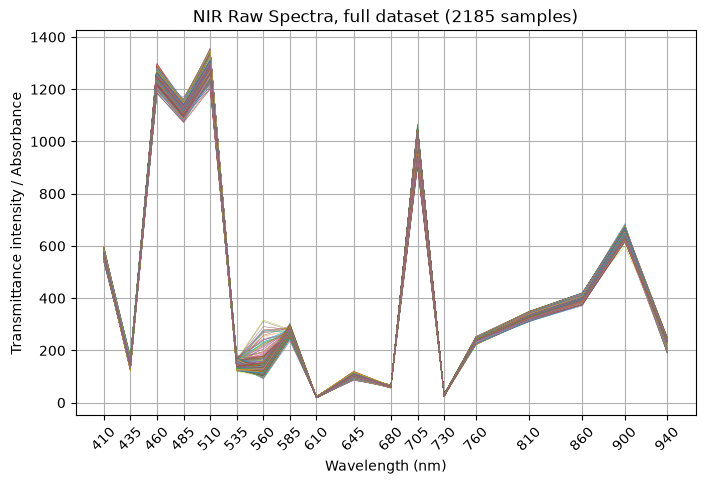

In [4]:
spectra_plot (df_raw[wavelengths], 'NIR Raw Spectra, full dataset')

In [5]:
# Tính absorbance lưu vào df_normalized
df_normalized = df_hcmut.copy()
group_id = (df_normalized['Sample_ID'] == 'Calib').cumsum()
wavelength_columns = list(wavelengths)
df_normalized.loc[:, wavelength_columns] = (
    df_normalized.groupby(group_id, sort=False)[wavelength_columns]
    .transform(lambda x: -np.log(x / x.iloc[0]))
)

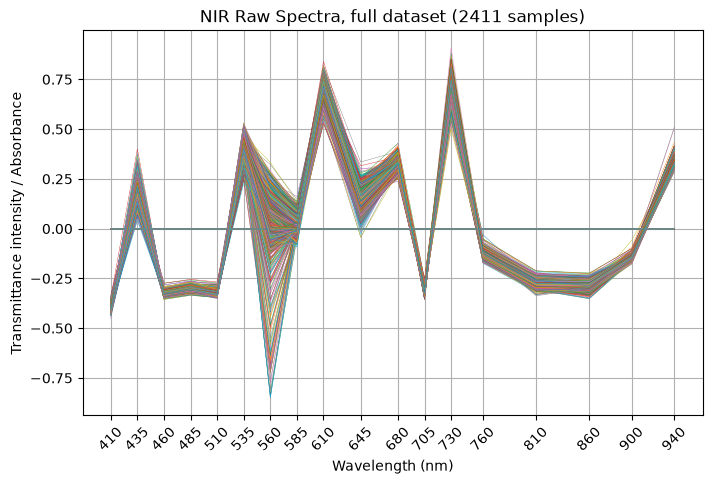

In [6]:
spectra_plot (df_normalized[wavelengths], 'NIR Raw Spectra, full dataset')

### **Training**

#### **Chia tập training, testing**

In [7]:
df_sorted = df_raw.set_index('Sample_ID').sort_values(by='pH (Horiba)')
df_sorted['Group_ID'] = df_sorted.groupby("pH (Horiba)").ngroup()

is_train = df_sorted['Group_ID'] % 3 < 2
is_test = df_sorted['Group_ID'] % 3 == 2

X_train = df_sorted.loc[is_train, wavelengths]
y_train = df_sorted.loc[is_train, 'pH (Horiba)']

X_test = df_sorted.loc[is_test, wavelengths]
y_test = df_sorted.loc[is_test, 'pH (Horiba)']

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")

Train size: 1441
Test size: 744


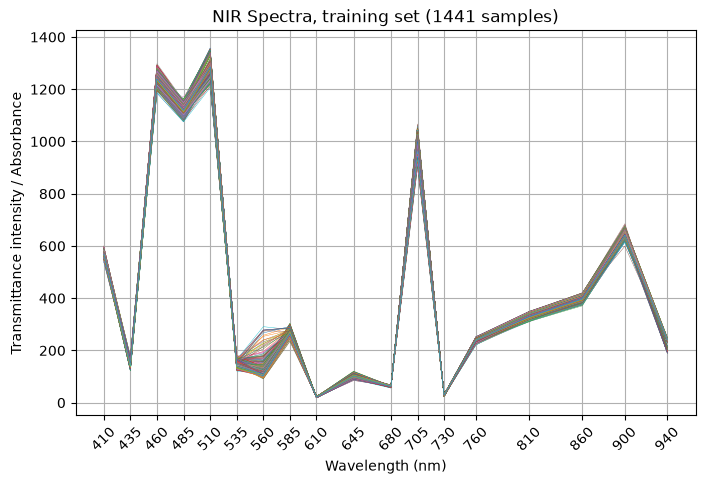

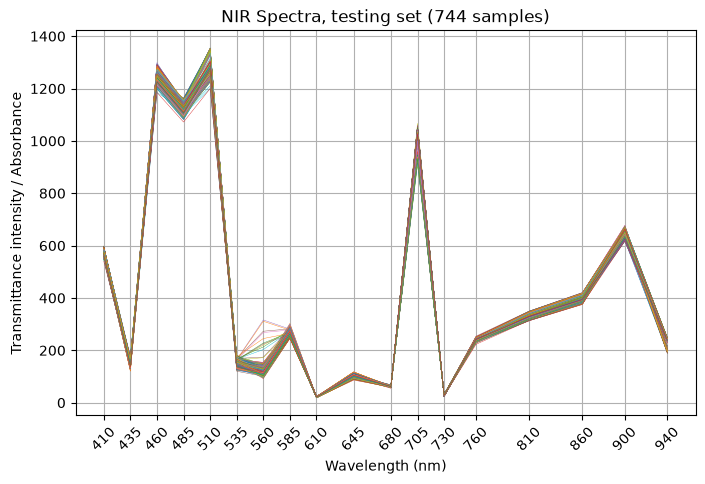

In [11]:
spectra_plot (pd.DataFrame(X_train, columns=wavelengths), 'NIR Spectra, training set')
spectra_plot (pd.DataFrame(X_test, columns=wavelengths), 'NIR Spectra, testing set')

#### **Tiền xử lý**

##### **Standard Normal Variate**

In [12]:
snv = StandardNormalVariate()
X_train_snv = snv.fit_transform(X_train)
X_test_snv = snv.transform(X_test)
X_train_snv = pd.DataFrame(X_train_snv, columns=X_train.columns, index=X_train.index)
X_test_snv = pd.DataFrame(X_test_snv, columns=X_test.columns, index=X_test.index)

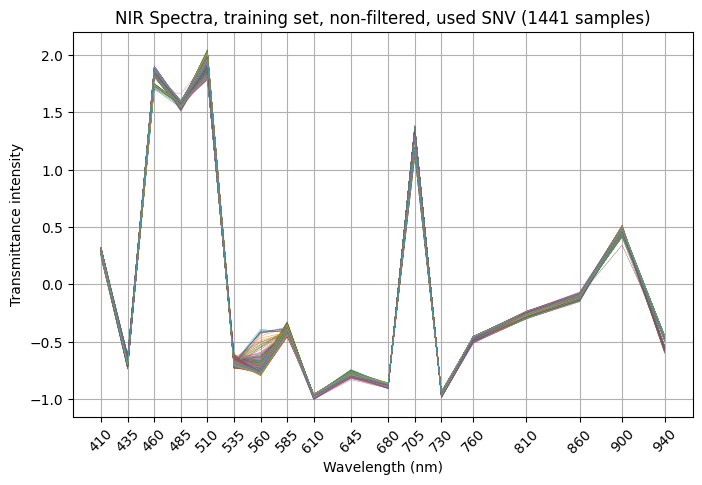

In [ ]:
spectra_plot(X_train_snv, 'NIR Spectra, training set, non-filtered, used SNV')

##### **Multiplicative Scatter Correction**

In [20]:
msc = MultiplicativeScatterCorrection()
X_train_msc = msc.fit_transform(X_train)
X_test_msc = msc.transform(X_test)
X_train_msc = pd.DataFrame(X_train_msc, columns=X_train.columns, index=X_train.index)
X_test_msc = pd.DataFrame(X_test_msc, columns=X_test.columns, index=X_test.index)

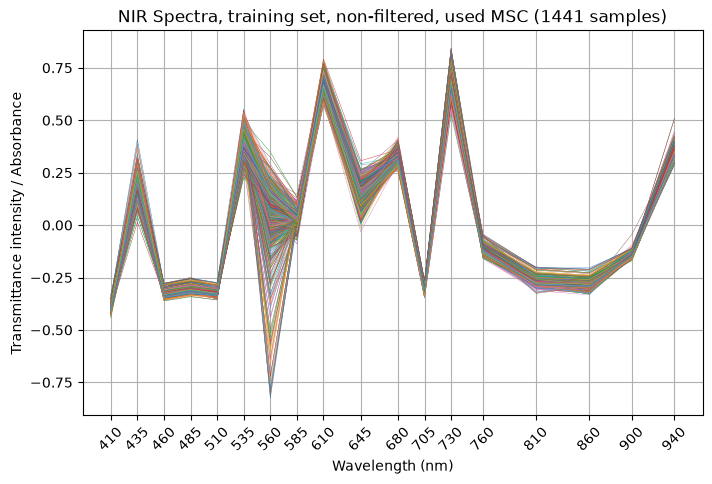

In [ ]:
spectra_plot (X_train_msc, 'NIR Spectra, training set, non-filtered, used MSC')

##### **SNV + MSC**

In [ ]:
snv_msc = MultiplicativeScatterCorrection()
X_train_snv_msc = snv_msc.fit_transform(X_train_snv)
X_test_snv_msc = snv_msc.transform(X_test_snv)
X_train_snv_msc = pd.DataFrame(X_train_snv_msc, columns=X_train.columns, index=X_train.index)
X_test_snv_msc = pd.DataFrame(X_test_snv_msc, columns=X_test.columns, index=X_test.index)

In [ ]:
spectra_plot (X_train_snv_msc,
              'NIR Spectra, training set, non-filtered, used SNV + MSC')

##### **Standard Scaler**

In [8]:
ss = StandardScaler()
X_train_ss = ss.fit_transform(X_train)
X_test_ss = ss.transform(X_test)
X_train_ss = pd.DataFrame(X_train_ss, columns=X_train.columns, index=X_train.index)
X_test_ss = pd.DataFrame(X_test_ss, columns=X_test.columns, index=X_test.index)

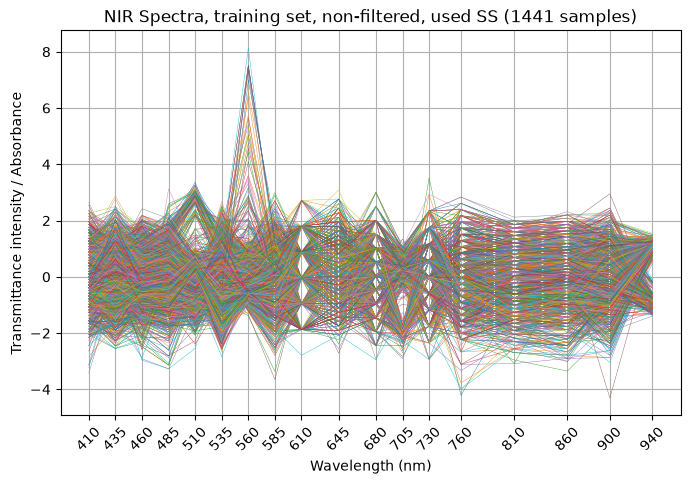

In [9]:
spectra_plot (X_train_ss,
              'NIR Spectra, training set, non-filtered, used SS')

##### **SNV + SS**

In [ ]:
snv_ss = StandardScaler()
X_train_snv_ss = snv_ss.fit_transform(X_train_snv)
X_test_snv_ss = snv_ss.transform(X_test_snv)
X_train_snv_ss = pd.DataFrame(X_train_snv_ss, columns=X_train.columns, index=X_train.index)
X_test_snv_ss = pd.DataFrame(X_test_snv_ss, columns=X_test.columns, index=X_test.index)

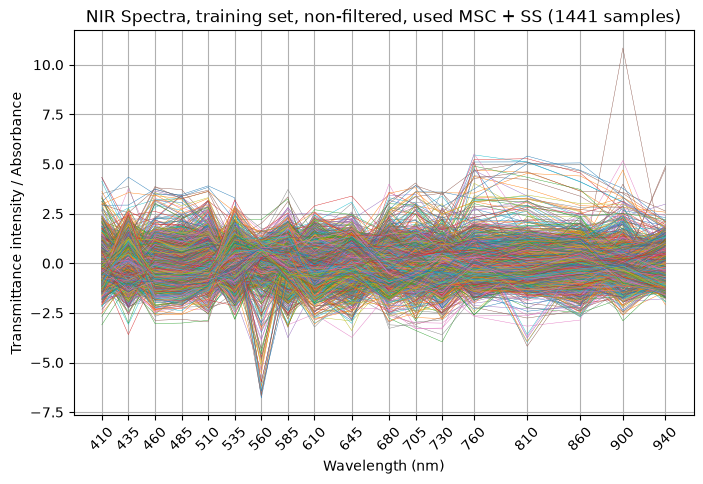

In [ ]:
spectra_plot (X_train_snv_ss,
              'NIR Spectra, training set, non-filtered, used SNV + SS')

##### **MSC + SS**

In [22]:
msc_ss = StandardScaler()
X_train_msc_ss = msc_ss.fit_transform(X_train_msc)
X_test_msc_ss = msc_ss.transform(X_test_msc)
X_train_msc_ss = pd.DataFrame(X_train_msc_ss, columns=X_train.columns, index=X_train.index)
X_test_msc_ss = pd.DataFrame(X_test_msc_ss, columns=X_test.columns, index=X_test.index)

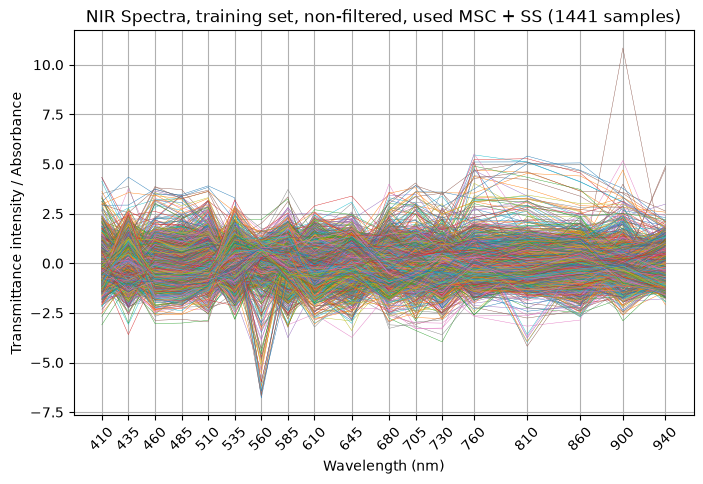

In [ ]:
spectra_plot (X_train_msc_ss,
              'NIR Spectra, training set, non-filtered, used MSC + SS')

##### **Robust Scaler**

In [18]:
rs = RobustScaler()
X_train_rs = rs.fit_transform(X_train)
X_test_rs = rs.transform(X_test)
X_train_rs = pd.DataFrame(X_train_rs, columns=X_train.columns, index=X_train.index)
X_test_rs = pd.DataFrame(X_test_rs, columns=X_test.columns, index=X_test.index)

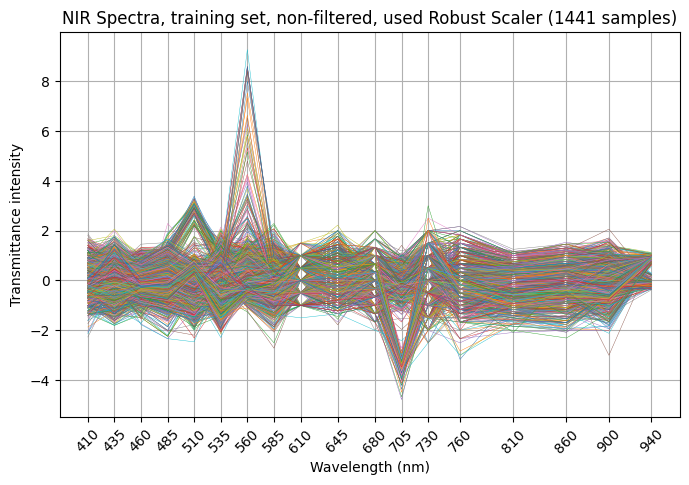

In [ ]:
spectra_plot (X_train_rs,
              'NIR Spectra, training set, non-filtered, used Robust Scaler')

##### **MinMax Scaler**

In [22]:
mm = MinMaxScaler()
X_train_mm = mm.fit_transform(X_train)
X_test_mm = mm.transform(X_test)
X_train_mm = pd.DataFrame(X_train_mm, columns=X_train.columns, index=X_train.index)
X_test_mm = pd.DataFrame(X_test_mm, columns=X_test.columns, index=X_test.index)

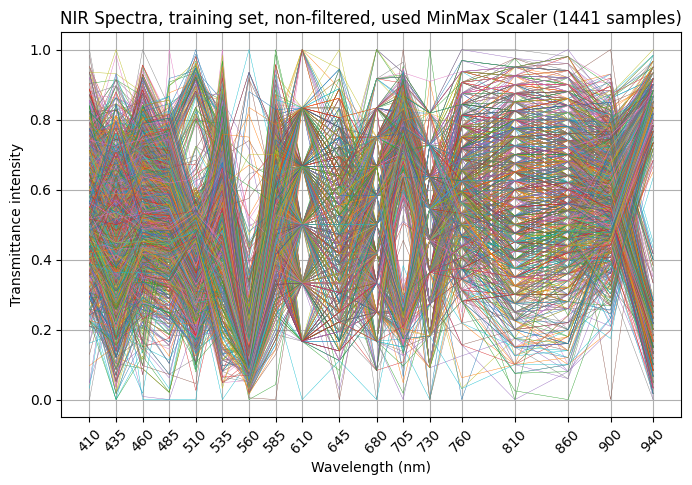

In [23]:
spectra_plot (X_train_mm,
              'NIR Spectra, training set, non-filtered, used MinMax Scaler')

##### **SNV + MM**

In [ ]:
snv_mm = MinMaxScaler()
X_train_snv_mm = snv_mm.fit_transform(X_train_snv)
X_test_snv_mm = snv_mm.transform(X_test_snv)
X_train_snv_mm = pd.DataFrame(X_train_snv_mm, columns=X_train.columns, index=X_train.index)
X_test_snv_mm = pd.DataFrame(X_test_snv_mm, columns=X_test.columns, index=X_test.index)

In [ ]:
spectra_plot (X_train_snv_mm,
              'NIR Spectra, training set, non-filtered, used MinMax Scaler')

##### **MSC + MM**

In [ ]:
msc_mm = MinMaxScaler()
X_train_msc_mm = msc_mm.fit_transform(X_train_msc)
X_test_msc_mm = msc_mm.transform(X_test_msc)
X_train_msc_mm = pd.DataFrame(X_train_msc_mm, columns=X_train.columns, index=X_train.index)
X_test_msc_mm = pd.DataFrame(X_test_msc_mm, columns=X_test.columns, index=X_test.index)

In [ ]:
spectra_plot (X_train_msc_mm,
              'NIR Relative Spectra, training set, non-filtered, used MSC + MinMax')

##### **MRMR**

In [ ]:
sel = MRMR(method='FCQ', max_features=8)
sel.fit(X_train, y_train);

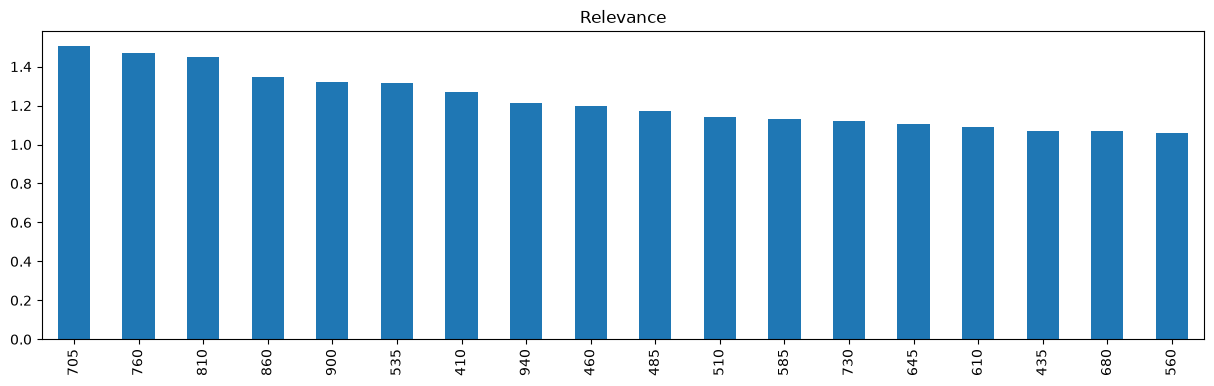

In [14]:
pd.Series(sel.relevance_, index=sel.variables_).sort_values(
    ascending=False).plot.bar(figsize=(15, 4))
plt.title("Relevance")
plt.show()

In [17]:
wavelengths_mrmr = wavelengths[sel.get_support()]
X_train_mrmr = X_train[wavelengths_mrmr]
X_test_mrmr = X_test[wavelengths_mrmr]

In [18]:
X_train_mrmr

,410,510,560,610,645,705,730,810
Sample_ID,,,,,,,,
758,573.0,1270.0,120.0,20.0,108.0,1031.0,24.0,337.0
736,577.0,1275.0,110.0,20.0,98.0,1038.0,27.0,339.0
660,584.0,1244.0,111.0,21.0,114.0,1046.0,25.0,340.0
710,587.0,1290.0,110.0,21.0,106.0,1057.0,27.0,345.0
729,586.0,1288.0,110.0,21.0,104.0,1051.0,27.0,343.0
...,...,...,...,...,...,...,...,...
1978,568.0,1287.0,107.0,20.0,93.0,944.0,30.0,328.0
2025,577.0,1312.0,117.0,20.0,99.0,1024.0,27.0,334.0
2015,564.0,1275.0,107.0,22.0,106.0,939.0,29.0,325.0


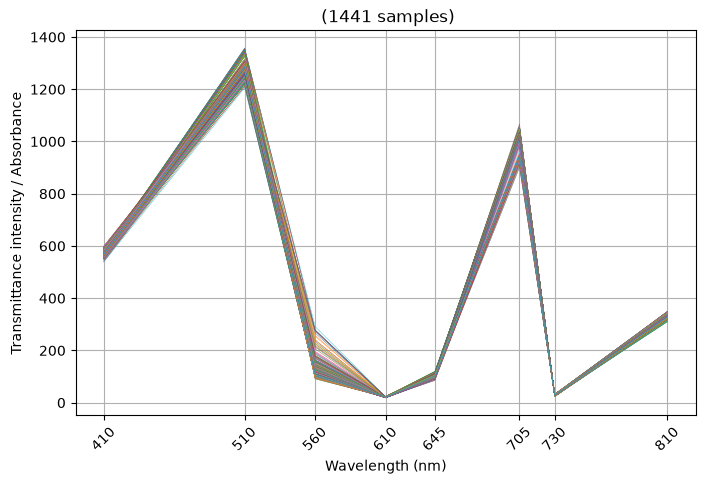

In [19]:
spectra_plot(X_train_mrmr)

##### **F-test**

In [ ]:
# Tính F-score cho từng bước sóng (chuẩn hóa SS trước)
f_scores, p_values = f_regression(X_train_ss, y_train)
mean_f_score = np.mean(f_scores)

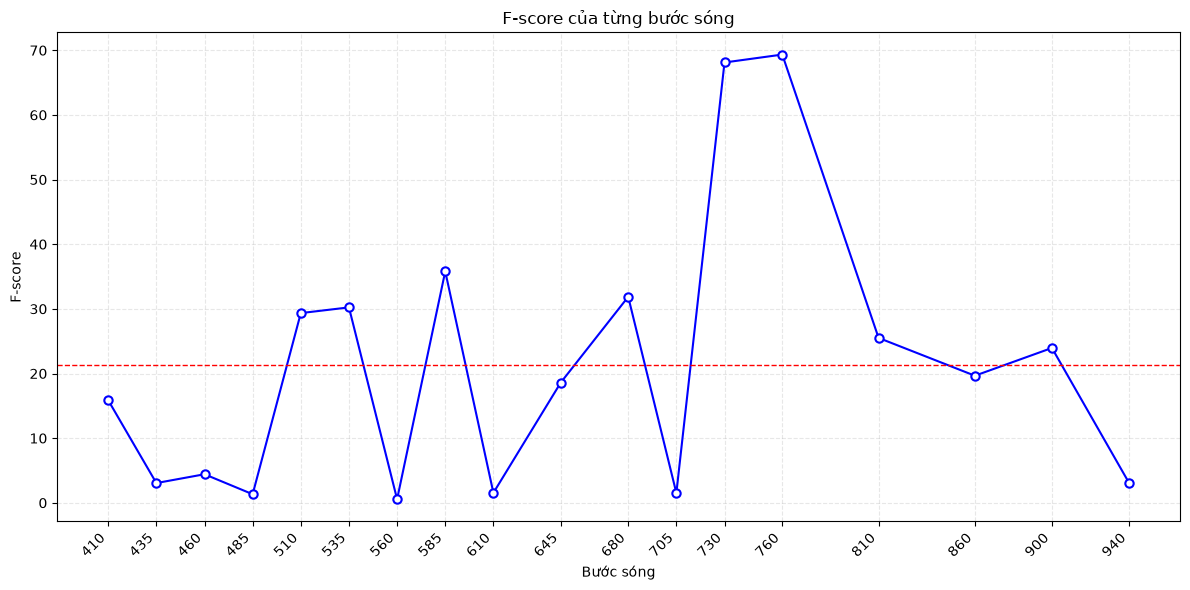

In [11]:
# Vẽ biểu đồ F-score của từng bước sóng
plt.figure(figsize=(12, 6))
plt.plot(
    wavelengths,
    f_scores,
    color="blue",          
    linestyle="-",
    linewidth=1.5,
    marker="o",
    markersize=6,
    markerfacecolor="white", 
    markeredgecolor="blue",  
    markeredgewidth=1.5
)
plt.axhline(
    y=float(mean_f_score),
    color='red',
    linestyle="--",
    linewidth=1.0
)
int_wavelengths = np.asarray(wavelengths, dtype=int)
plt.xticks(
    ticks=int_wavelengths,
    labels=[f"{wavelength}" for wavelength in int_wavelengths],
    rotation=45,
    ha="right"
)
plt.xlabel("Bước sóng")
plt.ylabel("F-score")
plt.title("F-score của từng bước sóng")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Chọn các bước sóng có F-score lớn hơn mean_f_score
wavelengths_F_test = [wavelength for wavelength, f_score 
                      in zip(wavelengths, f_scores) 
                      if f_score > mean_f_score]
X_train_ss_F_test = X_train_ss[wavelengths_F_test]
X_test_ss_F_test = X_test_ss[wavelengths_F_test]

##### **SFS**

In [21]:
sfs = SequentialFeatureSelector(
    estimator = SVR(kernel='rbf'),
    n_features_to_select=8,
    direction='forward',
    scoring='r2',
    cv=5
)
sfs.fit(X_train, y_train)

,estimator estimator: estimator instanceAn unfitted estimator.,SVR()
,"n_features_to_select n_features_to_select: ""auto"", int or float, default=""auto""If `""auto""`, the behaviour depends on the `tol` parameter:- if `tol` is not `None`, then features are selected while the score change does not exceed `tol`.- otherwise, half of the features are selected.If integer, the parameter is the absolute number of features to select.If float between 0 and 1, it is the fraction of features to select... versionadded:: 1.1 The option `""auto""` was added in version 1.1... versionchanged:: 1.3 The default changed from `""warn""` to `""auto""` in 1.3.",8
,"scoring scoring: str or callable, default=NoneScoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)`` that returns a single value. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.",'r2'
,"tol tol: float, default=NoneIf the score is not incremented by at least `tol` between twoconsecutive feature additions or removals, stop adding or removing.`tol` can be negative when removing features using `direction=""backward""`.`tol` is required to be strictly positive when doing forward selection.It can be useful to reduce the number of features at the cost of a smalldecrease in the score.`tol` is enabled only when _features_to_select` is `""auto""`... versionadded:: 1.1",None
,"direction direction: {'forward', 'backward'}, default='forward'Whether to perform forward selection or backward selection.",'forward'
,"cv cv: int, cross-validation generator or an iterable, default=5Determines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. In all othercases, :class:`~sklearn.model_selection.KFold` is used. These splittersare instantiated with `shuffle=False` so the splits will be the sameacross calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel. When evaluating a new feature toadd or remove, the cross-validation procedure is parallel over thefolds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,18
n_features_to_select_ n_features_to_select_: intThe number of features that were selected.,int64,np.int64(8)
"support_ support_: ndarray of shape (n_features,), dtype=boolThe mask of selected features.","ndarray[bool](18,)","[ True,False, True,..., True, True, True]"


In [22]:
wavelengths_sfs = wavelengths[sfs.get_support()]
X_train_sfs = X_train[wavelengths_sfs]
X_test_sfs = X_test[wavelengths_sfs]

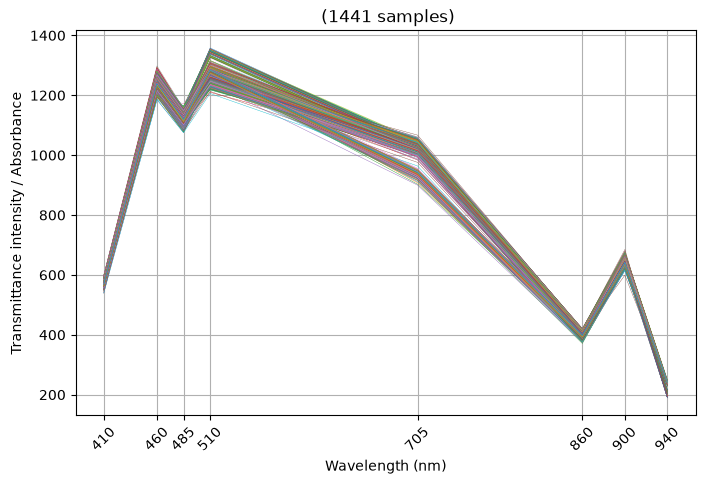

In [23]:
spectra_plot(X_train_sfs)

#### **Support Vector Regression**

In [ ]:
# Tạo dải hyperparams
pbounds = {
    'log_C': (0, 3.0),
    'log_gamma': (-3.0, 1.0),
    'epsilon': (0.001, 1.0)
}

In [ ]:
# Tạo bảng svr_training lưu method + optimized hyperparams
svr_training = pd.DataFrame(columns=['Method', 'Validation -MSE', 'Best_C', 'Best_gamma', 'Best_epsilon'])

##### **SVR with raw data**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train, X_test, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError(
        "Bayesian optimization produced no result; ensure maximize() completed."
    )

print(f"Best params: {best['params']}")
p, target = best['params'], best['target']

# Cập nhật method + tham số tối ưu vào svr_training
svr_training.loc[len(svr_training)] = ['SVR + raw data', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -4.034853 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -1.256451 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -4.033619 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -1.268809 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.345879 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.344640 | 0.0       | -3.0      | 0.001     |
| 7         | -2.705902 | 3.0       | -3.0      | 0.001     |
| 8         | -3.878195 | 3.0       | -1.009830 | 1.0       |
| 9         | -1.238256 | 0.7160155 | -3.0      | 1.0       |
| 10        | -2.295241 | 0.0       | -1.943494 | 1.0       |
| 11        | -1.059035 | 1.0285852 | -3.0      | 0.001     |
| 12        | -1.382533 | 0.7171141 | -2.069747 | 0.001     |
| 13        | -1.637835 | 1.4967078 | -2.229994 | 1.0       |
| 14        | -1.070901 | 1.4146274 | -3.0      | 0.6788421 |
| 15    

--- SVR, (C, gamma, epsilon) = (10.50, 0.00, 0.09) ---
Training RMSE: 0.6478
Testing RMSE: 1.0125
Training R²: 0.896
Testing R²: 0.7458


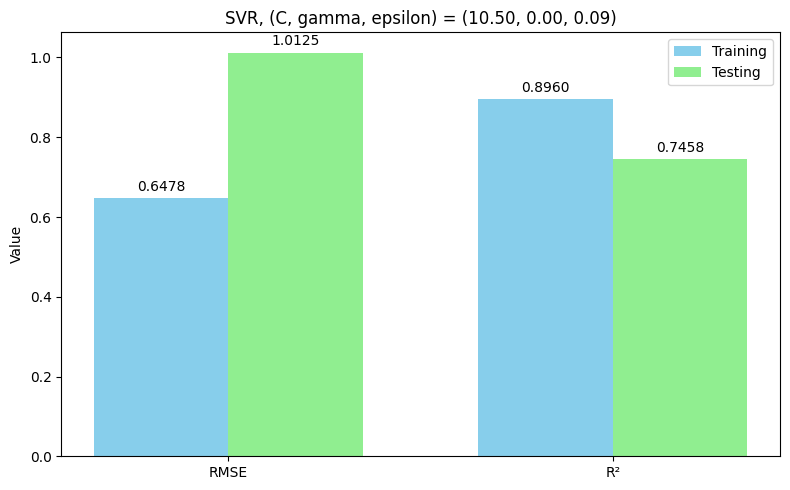

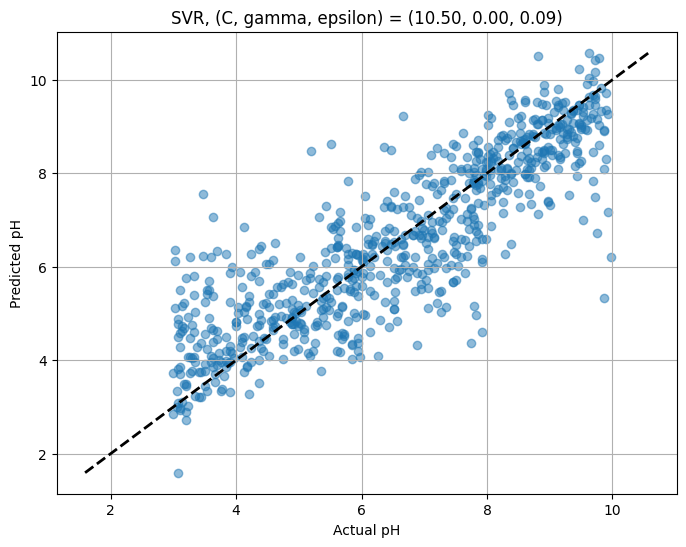

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + raw data"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train, y_train)
metrics_calculation(svr, X_train, y_train, X_test, y_test,
                    f'SVR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SNV**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_snv, X_test_snv, y_train, y_test), 
                                 pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -2.257073 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.821550 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.833389 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.879136 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.487822 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.799214 | 2.7941271 | 1.0       | 0.6452364 |
| 7         | -1.843045 | 3.0       | 1.0       | 0.001     |
| 8         | -1.767284 | 3.0       | 1.0       | 1.0       |
| 9         | -1.832264 | 2.5619583 | 1.0       | 1.0       |
| 10        | -1.952434 | 3.0       | 0.6403075 | 1.0       |
| 11        | -1.771864 | 3.0       | 1.0       | 0.7164927 |
| 12        | -1.763753 | 3.0       | 1.0       | 0.9097887 |
| 13        | -1.770375 | 3.0       | 1.0       | 0.8883550 |
| 14        | -1.770375 | 3.0       | 1.0       | 0.8883550 |
| 15    

--- SVR + SNV, (C, gamma, epsilon) = (1000.00, 10.00, 0.91) ---
Training RMSE: 1.2183
Testing RMSE: 1.3281
Training R²: 0.6321
Testing R²: 0.5626


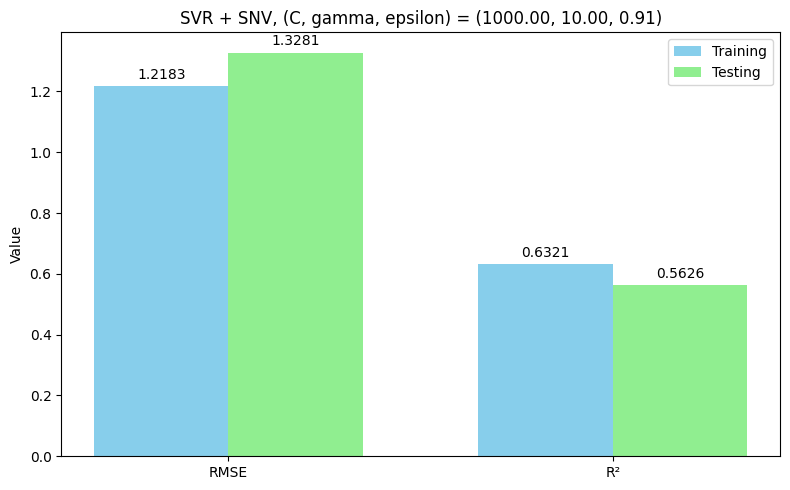

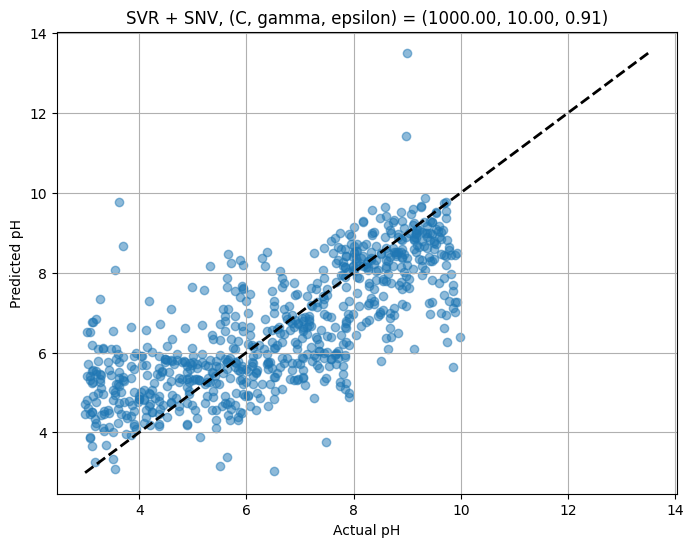

In [36]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv, y_train)
metrics_calculation(svr_snv, X_train_snv, y_train, X_test_snv, y_test,
                    f'SVR + SNV, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + MSC**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_msc, X_test_msc, y_train, y_test), 
                                 pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -4.034853 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -1.457931 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -4.033617 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -1.621998 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.392404 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.987529 | 3.0       | -3.0      | 0.001     |
| 7         | -2.665827 | 2.2174175 | -1.419659 | 1.0       |
| 8         | -1.484050 | 0.6134141 | -3.0      | 1.0       |
| 9         | -1.682248 | 0.0       | -3.0      | 0.001     |
| 10        | -1.774443 | 0.0       | -1.978962 | 1.0       |
| 11        | -3.397345 | 3.0       | -0.981875 | 0.001     |
| 12        | -1.363782 | 0.5919102 | -1.965109 | 0.001     |
| 13        | -1.385625 | 1.0129622 | -3.0      | 0.001     |
| 14        | -1.480333 | 1.1387523 | -2.265716 | 1.0       |
| 15    

--- SVR + MSC, (C, gamma, epsilon) = (10.14, 0.00, 0.11) ---
Training RMSE: 0.5781
Testing RMSE: 1.1132
Training R²: 0.9171
Testing R²: 0.6927


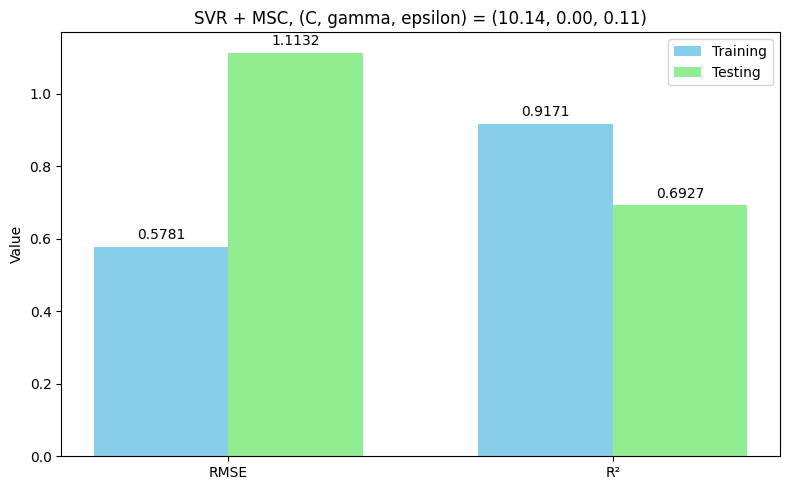

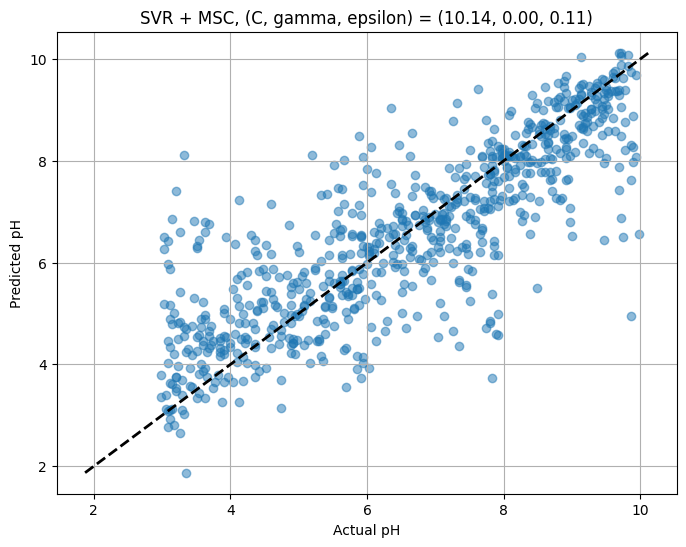

In [39]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_msc, y_train)
metrics_calculation(svr_msc, X_train_msc, y_train, X_test_msc, y_test,
                    f'SVR + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SNV + MSC**

In [42]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_snv_msc, X_test_snv_msc, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MSC', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -2.257171 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.821828 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.834176 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.879433 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.490485 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.795020 | 2.7977205 | 1.0       | 0.6581679 |
| 7         | -1.843488 | 3.0       | 1.0       | 0.001     |
| 8         | -1.767656 | 3.0       | 1.0       | 1.0       |
| 9         | -1.834628 | 2.5471994 | 1.0       | 1.0       |
| 10        | -1.964684 | 3.0       | 0.6125727 | 0.9785989 |
| 11        | -1.773862 | 3.0       | 1.0       | 0.6986723 |
| 12        | -1.764501 | 3.0       | 1.0       | 0.9085569 |
| 13        | -2.069885 | 1.9540736 | 1.0       | 0.001     |
| 14        | -1.771186 | 3.0       | 1.0       | 0.8852816 |
| 15    

--- SVR + SNV + MSC, (C, gamma, epsilon) = (1000.00, 10.00, 0.91) ---
Training RMSE: 1.2184
Testing RMSE: 1.3283
Training R²: 0.632
Testing R²: 0.5624


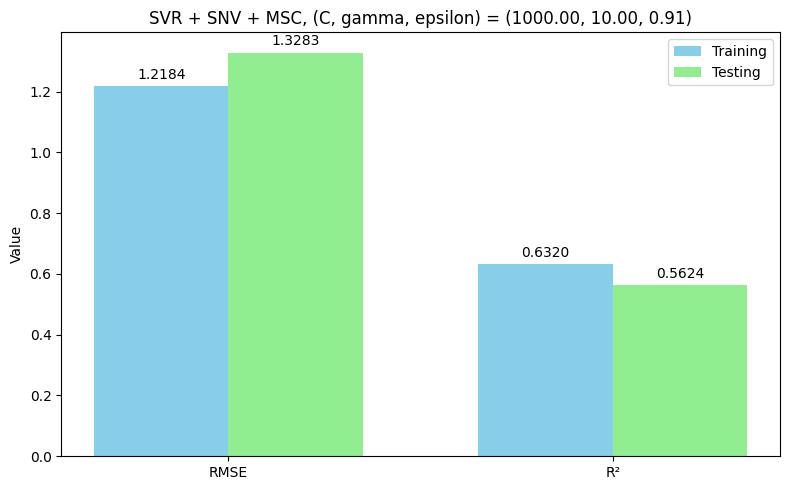

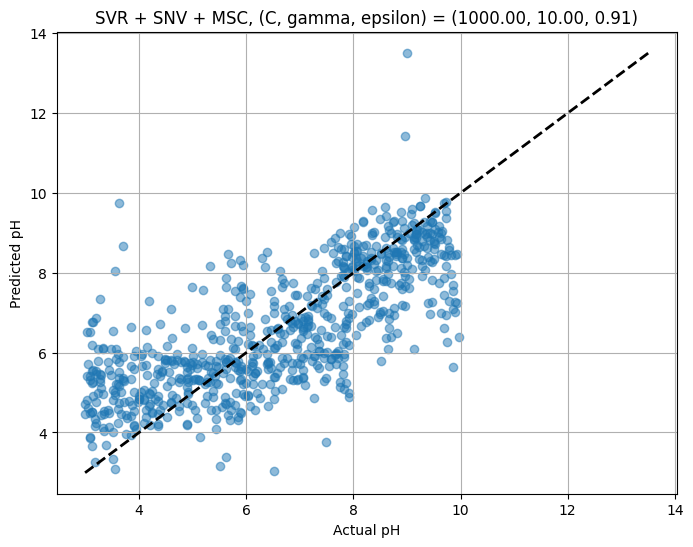

In [44]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MSC"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_msc = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_msc, y_train)
metrics_calculation(svr_snv_msc, X_train_snv_msc, y_train, X_test_snv_msc, y_test,
                    f'SVR + SNV + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MSC, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SS**

In [55]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_ss, X_test_ss, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.716155 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -1.866939 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.219245 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.225217 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.619818 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.519846 | 3.0       | -0.914634 | 0.001     |
| 7         | -1.935046 | 3.0       | -3.0      | 0.001     |
| 8         | -3.367614 | 0.0       | -3.0      | 0.001     |
| 9         | -1.553918 | 3.0       | -1.955191 | 1.0       |
| 10        | -1.454693 | 1.9987005 | -1.552357 | 1.0       |
| 11        | -1.562398 | 0.9218639 | -1.504359 | 1.0       |
| 12        | -1.396603 | 1.2830446 | -1.292002 | 0.001     |
| 13        | -1.564930 | 0.0       | -1.128249 | 0.001     |
| 14        | -1.666737 | 0.0       | -1.189402 | 1.0       |
| 15    

--- SVR + SS, (C, gamma, epsilon) = (13.44, 0.20, 0.18) ---
Training RMSE: 0.5415
Testing RMSE: 1.0799
Training R²: 0.9273
Testing R²: 0.7108


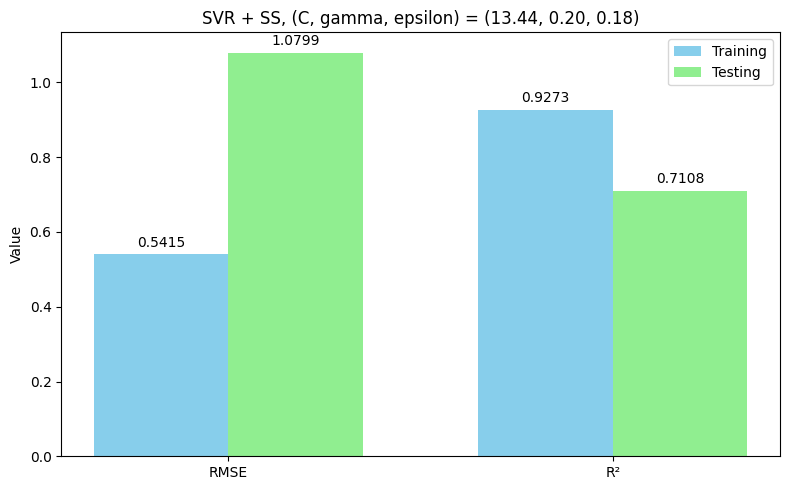

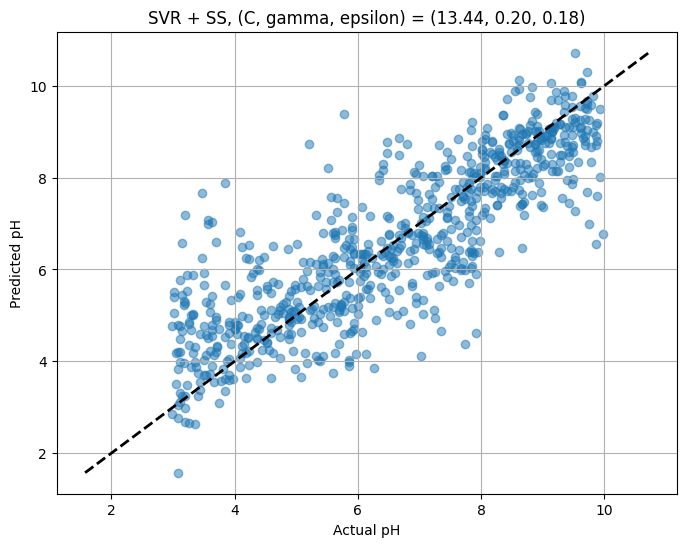

In [57]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_ss, y_train)
metrics_calculation(svr_ss, X_train_ss, y_train, X_test_ss, y_test,
                    f'SVR + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SNV + SS**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_snv_ss, X_test_snv_ss, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.876580 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.467797 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.545709 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.737169 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.065391 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -3.564991 | 3.0       | -1.009417 | 0.001     |
| 7         | -2.469711 | 2.8893012 | -2.862213 | 0.001     |
| 8         | -2.096159 | 3.0       | -2.187617 | 1.0       |
| 9         | -3.570557 | 0.0       | -3.0      | 0.001     |
| 10        | -1.977159 | 2.1343108 | -1.717376 | 1.0       |
| 11        | -2.091740 | 1.0471245 | -1.465006 | 1.0       |
| 12        | -2.478689 | 0.0       | -1.370947 | 1.0       |
| 13        | -1.937870 | 1.0810450 | -1.242652 | 0.001     |
| 14        | -2.120370 | 0.1367253 | -1.089833 | 0.001     |
| 15    

--- SVR + SNV + SS, (C, gamma, epsilon) = (9.26, 0.24, 0.17) ---
Training RMSE: 0.4984
Testing RMSE: 1.287
Training R²: 0.9384
Testing R²: 0.5892


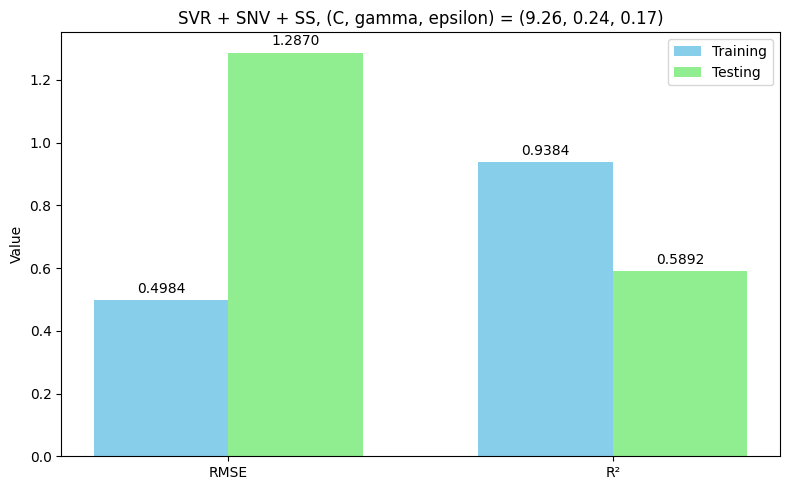

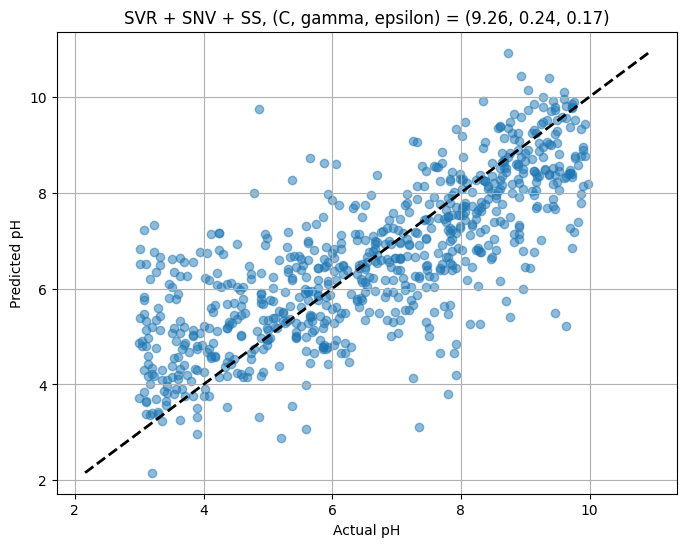

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + SS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_ss, y_train)
metrics_calculation(svr_snv_ss, X_train_snv_ss, y_train, X_test_snv_ss, y_test,
                    f'SVR + SNV + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',save_barchart=False, save_plot=True)

##### **SVR + MSC + SS**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_msc_ss, X_test_msc_ss, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC + SS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.915743 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.471059 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.614776 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.709040 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.074633 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.907794 | 3.0       | -0.977514 | 0.001     |
| 7         | -2.592965 | 3.0       | -3.0      | 0.001     |
| 8         | -2.383758 | 3.0       | -1.936443 | 1.0       |
| 9         | -3.444792 | 0.0       | -3.0      | 1.0       |
| 10        | -2.045706 | 2.0041639 | -1.574554 | 1.0       |
| 11        | -1.824710 | 1.6695834 | -1.321934 | 0.001     |
| 12        | -1.943813 | 0.6891656 | -1.308444 | 0.001     |
| 13        | -1.932963 | 0.9975302 | -1.248566 | 0.9521041 |
| 14        | -1.649471 | 1.3339258 | -0.916203 | 0.3952732 |
| 15    

--- SVR + MSC + SS, (C, gamma, epsilon) = (8.31, 0.22, 0.12) ---
Training RMSE: 0.4976
Testing RMSE: 1.2558
Training R²: 0.9386
Testing R²: 0.6089


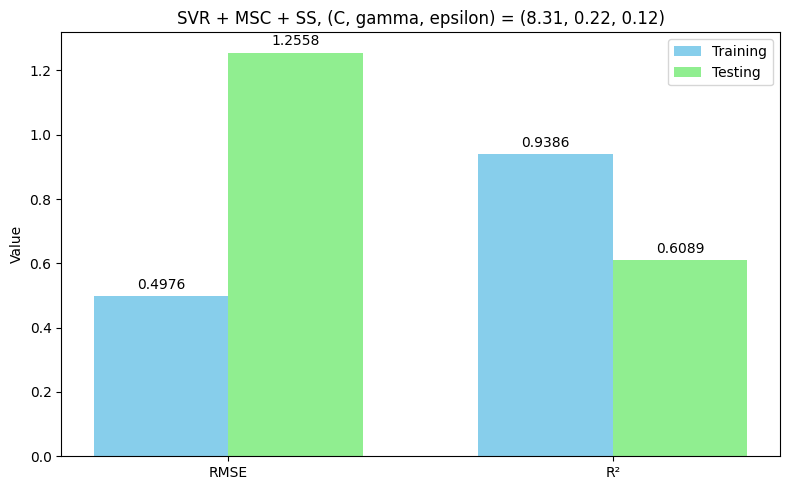

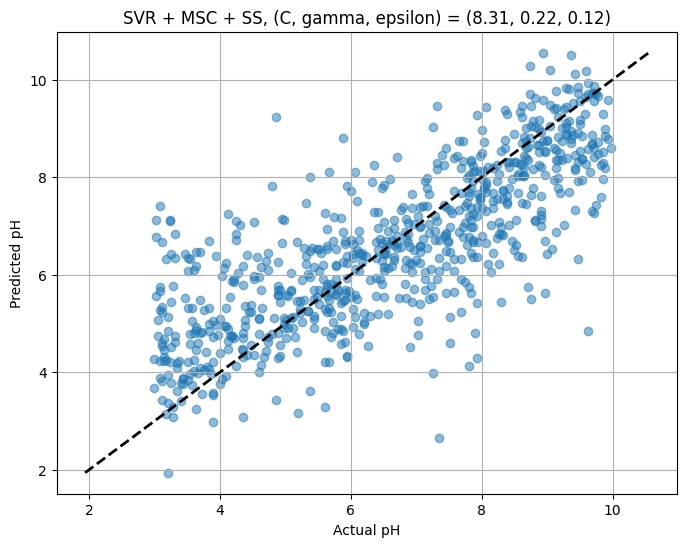

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC + SS"
                                    ,['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc_ss = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_msc_ss, y_train)
metrics_calculation(svr_msc_ss, X_train_msc_ss, y_train, X_test_msc_ss, y_test,
                    f'SVR + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC + SS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', save_barchart=False, save_plot=True)

##### **SVR + MM**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_mm, X_test_mm, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.500034 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.134435 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -1.606716 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.244998 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.792762 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.557144 | 3.0       | 1.0       | 0.001     |
| 7         | -1.697588 | 0.0       | 1.0       | 0.001     |
| 8         | -1.681540 | 3.0       | 1.0       | 1.0       |
| 9         | -1.926505 | 0.0       | 1.0       | 1.0       |
| 10        | -1.534244 | 1.7439807 | 0.1296985 | 0.001     |
| 11        | -1.495979 | 1.6504641 | 1.0       | 0.001     |
| 12        | -2.687290 | 0.0       | -0.472905 | 0.001     |
| 13        | -1.479623 | 3.0       | -0.333652 | 1.0       |
| 14        | -1.938180 | 3.0       | -0.211865 | 0.001     |
| 15    

--- SVR + MinMax, (C, gamma, epsilon) = (13.02, 4.73, 0.18) ---
Training RMSE: 0.6316
Testing RMSE: 1.1902
Training R²: 0.9012
Testing R²: 0.6485


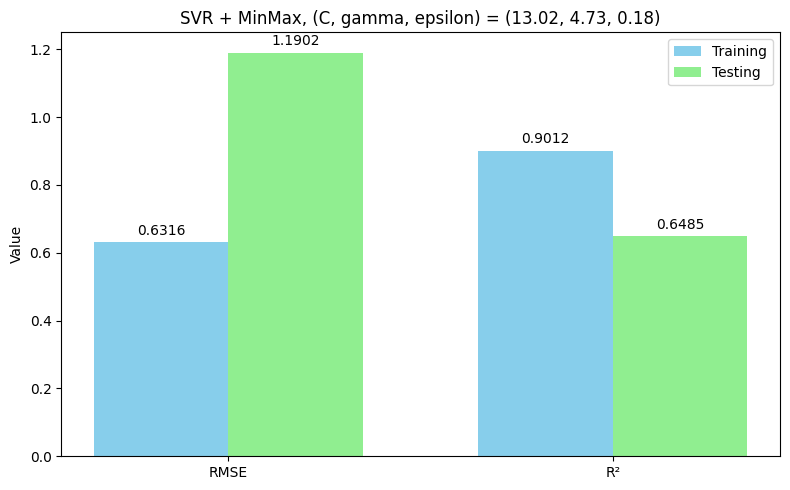

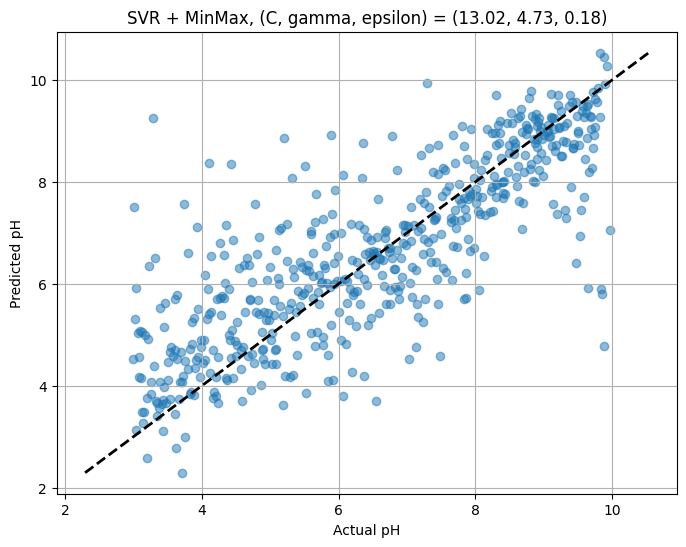

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_mm, y_train)
metrics_calculation(svr_mm, X_train_mm, y_train, X_test_mm, y_test,
                    f'SVR + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})', save_barchart=False, save_plot=True)

##### **SVR + SNV + MM**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_snv_mm, X_test_snv_mm, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SNV + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.447318 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.194769 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -1.703074 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.254227 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.761438 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.786051 | 3.0       | 1.0       | 0.001     |
| 7         | -2.036717 | 3.0       | 0.0590943 | 1.0       |
| 8         | -1.431312 | 0.9359485 | 1.0       | 0.001     |
| 9         | -1.771351 | 0.0       | 1.0       | 1.0       |
| 10        | -1.551423 | 1.6936191 | 0.3419219 | 0.001     |
| 11        | -1.643319 | 1.9579982 | 1.0       | 1.0       |
| 12        | -1.484046 | 1.6431883 | 1.0       | 0.001     |
| 13        | -1.428183 | 1.1270860 | 1.0       | 0.4002262 |
| 14        | -1.494793 | 1.0441322 | 0.5901781 | 0.001     |
| 15    

--- SVR + SNV + MinMax, (C, gamma, epsilon) = (28.43, 10.00, 0.26) ---
Training RMSE: 0.4236
Testing RMSE: 1.2937
Training R²: 0.9555
Testing R²: 0.5847


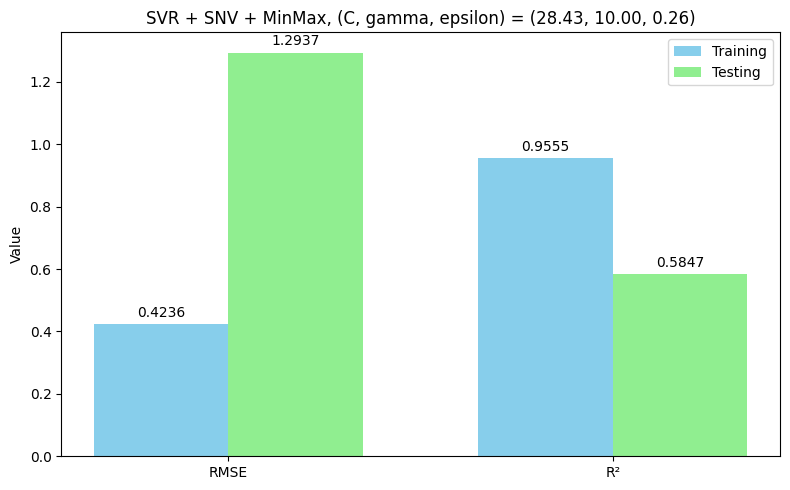

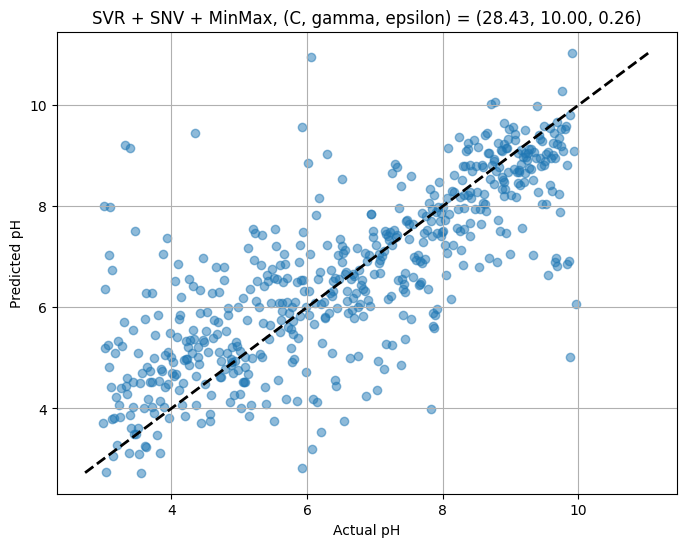

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SNV + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_snv_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_snv_mm, y_train)
metrics_calculation(svr_snv_mm, X_train_snv_mm, y_train, X_test_snv_mm, y_test,
                    f'SVR + SNV + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SNV + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + MSC + MM**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_msc_mm, X_test_msc_mm, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + MSC + MinMax', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -1.755850 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -3.220894 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.202072 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -3.248552 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -3.125992 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.019322 | 3.0       | 1.0       | 1.0       |
| 7         | -2.023264 | 1.8817029 | 1.0       | 0.001     |
| 8         | -1.979929 | 1.7767001 | 0.1736966 | 1.0       |
| 9         | -1.860622 | 1.6269718 | 1.0       | 1.0       |
| 10        | -1.677032 | 0.7202254 | 1.0       | 0.001     |
| 11        | -1.914859 | 1.0357714 | 0.2999999 | 0.001     |
| 12        | -2.242540 | 3.0       | -0.188803 | 1.0       |
| 13        | -1.672552 | 1.0509627 | 1.0       | 0.2549584 |
| 14        | -1.852203 | 0.7473347 | 1.0       | 1.0       |
| 15    

--- SVR + MSC + MinMax, (C, gamma, epsilon) = (7.36, 9.63, 0.29) ---
Training RMSE: 0.752
Testing RMSE: 1.2573
Training R²: 0.8599
Testing R²: 0.6077


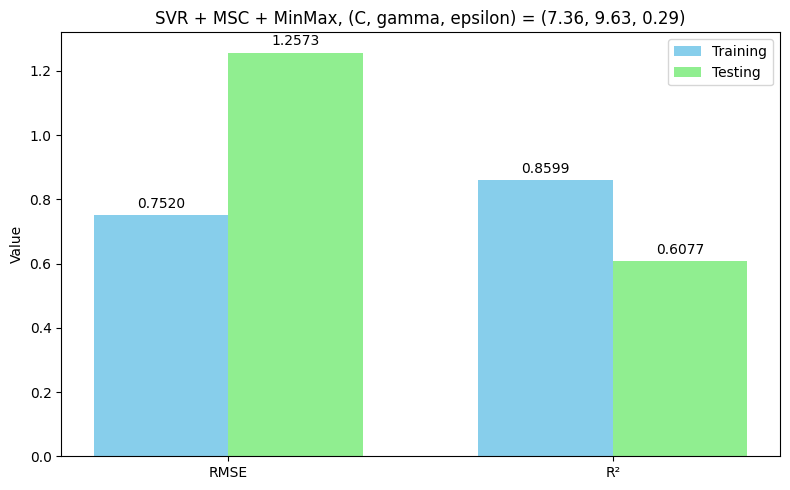

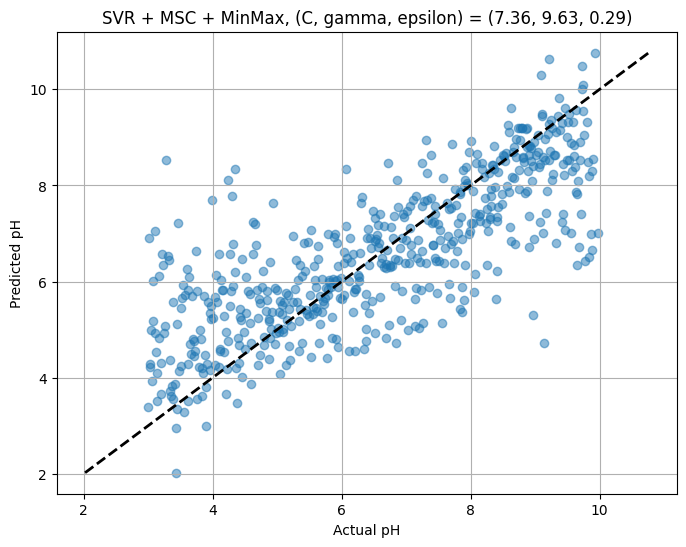

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MSC + MinMax"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_msc_mm = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_msc_mm, y_train)
metrics_calculation(svr_msc_mm, X_train_msc_mm, y_train, X_test_msc_mm, y_test,
                    f'SVR + MSC + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MSC + MinMax, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',save_barchart=False, save_plot=True)

##### **SVR + RS**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_rs, X_test_rs, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + RS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.686713 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.073319 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -3.057460 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.364761 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.779118 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.547894 | 3.0       | -0.993564 | 0.001     |
| 7         | -2.178555 | 3.0       | -3.0      | 0.001     |
| 8         | -3.515517 | 0.0       | -3.0      | 0.001     |
| 9         | -1.669065 | 3.0       | -1.936286 | 1.0       |
| 10        | -1.554480 | 2.0427528 | -1.528623 | 1.0       |
| 11        | -1.671014 | 0.9470394 | -1.415510 | 1.0       |
| 12        | -1.495162 | 1.2849702 | -1.214252 | 0.001     |
| 13        | -1.776975 | 0.0       | -1.040149 | 0.001     |
| 14        | -1.874485 | 0.0       | -1.107859 | 1.0       |
| 15    

--- SVR + RS, (C, gamma, epsilon) = (22.39, 0.17, 0.29) ---
Training RMSE: 0.6589
Testing RMSE: 1.1847
Training R²: 0.8924
Testing R²: 0.6517


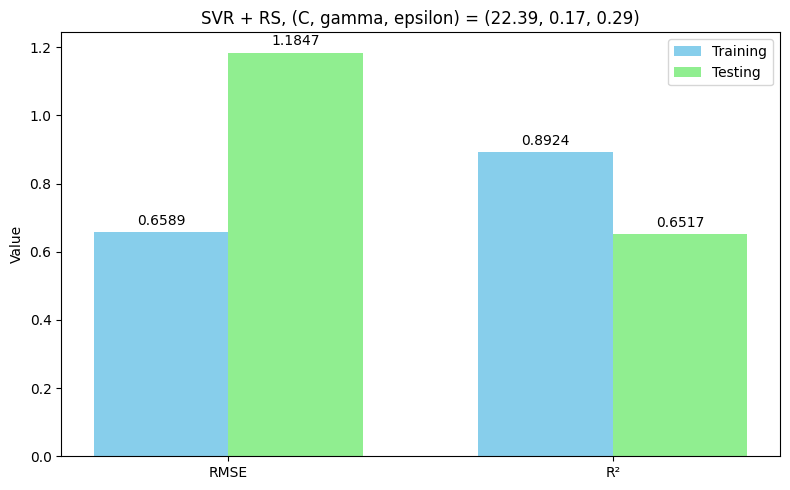

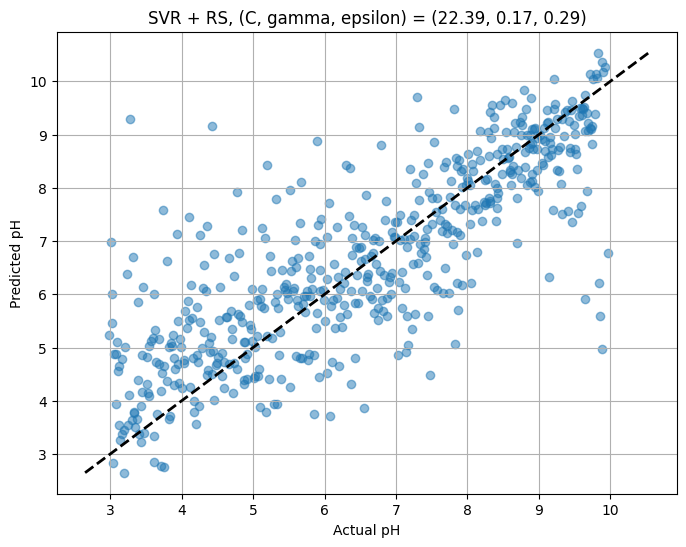

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + RS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr_rs = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_rs, y_train)
metrics_calculation(svr_rs, X_train_rs, y_train, X_test_rs, y_test,
                    f'SVR + RS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + RS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',save_barchart=False, save_plot=True)

##### **SVR + MRMR**

In [ ]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_mrmr, X_test_mrmr, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + MRMR', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -4.034851 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -1.549765 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -4.033514 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -1.552898 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.165411 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.865375 | 0.0       | -3.0      | 1.0       |
| 7         | -1.488451 | 0.8794763 | -3.0      | 0.001     |
| 8         | -1.502925 | 1.1502214 | -2.222654 | 1.0       |
| 9         | -1.485010 | 1.2111968 | -3.0      | 1.0       |
| 10        | -1.525222 | 0.0       | -2.064194 | 0.001     |
| 11        | -1.382185 | 0.9112928 | -2.014874 | 0.001     |
| 12        | -1.388005 | 0.8798408 | -2.451028 | 0.3685943 |
| 13        | -1.498049 | 1.8332473 | -3.0      | 0.001     |
| 14        | -1.432693 | 1.1241901 | -2.471448 | 0.001     |
| 15    

--- SVR + MRMR, (C, gamma, epsilon) = (6.34, 0.01, 0.20) ---
Training RMSE: 0.8259
Testing RMSE: 1.1594
Training R²: 0.8309
Testing R²: 0.6666


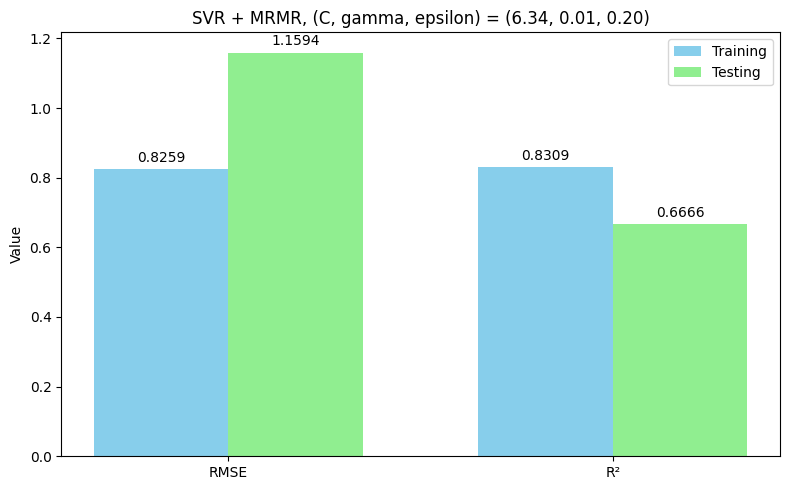

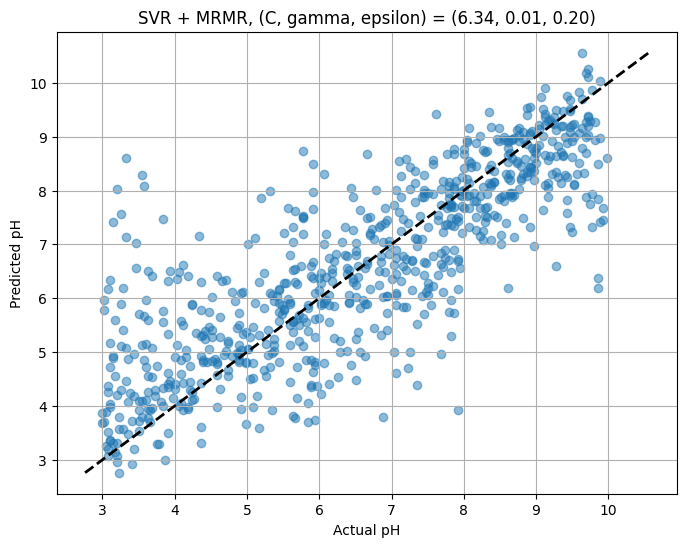

In [ ]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + MRMR"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_mrmr, y_train)
metrics_calculation(svr, X_train_mrmr, y_train, X_test_mrmr, y_test,
                    f'SVR + MRMR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + MRMR, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SS + F_test**

In [36]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_ss_F_test, X_test_ss_F_test, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SS + F_test', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -3.097826 | 1.1236203 | 0.8028572 | 0.7322619 |
| 2         | -2.716012 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -2.319877 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -2.946168 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -2.493489 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -2.318612 | 0.1664910 | 0.4626921 | 0.5952424 |
| 7         | -1.912934 | 0.0       | -0.062099 | 0.9387368 |
| 8         | -2.177777 | 0.0       | -0.858670 | 1.0       |
| 9         | -2.043068 | 0.0       | -0.638518 | 0.001     |
| 10        | -2.899345 | 0.0       | -1.783516 | 0.001     |
| 11        | -1.754726 | 0.5201105 | -0.428811 | 0.5411021 |
| 12        | -1.887037 | 1.1309207 | -0.650907 | 0.001     |
| 13        | -1.945390 | 1.3068554 | -0.801657 | 1.0       |
| 14        | -5.196571 | 3.0       | -0.529290 | 0.001     |
| 15    

--- SVR + SS + F_test, (C, gamma, epsilon) = (5.15, 0.71, 0.45) ---
Training RMSE: 0.7711
Testing RMSE: 1.2657
Training R²: 0.8526
Testing R²: 0.6027


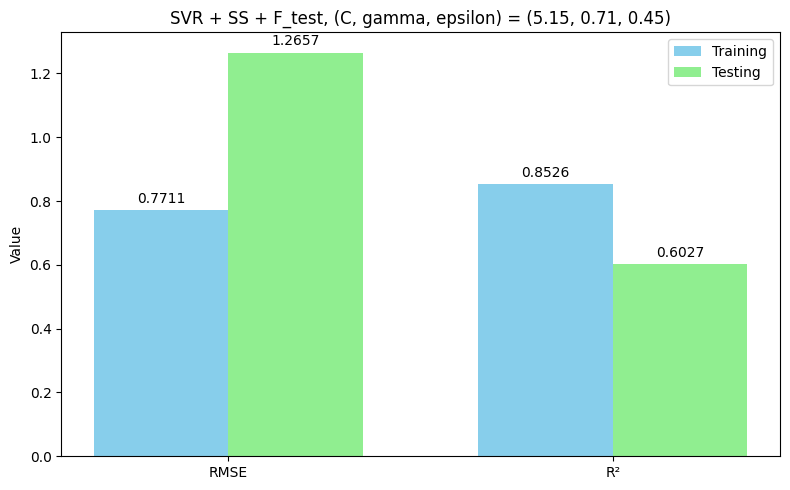

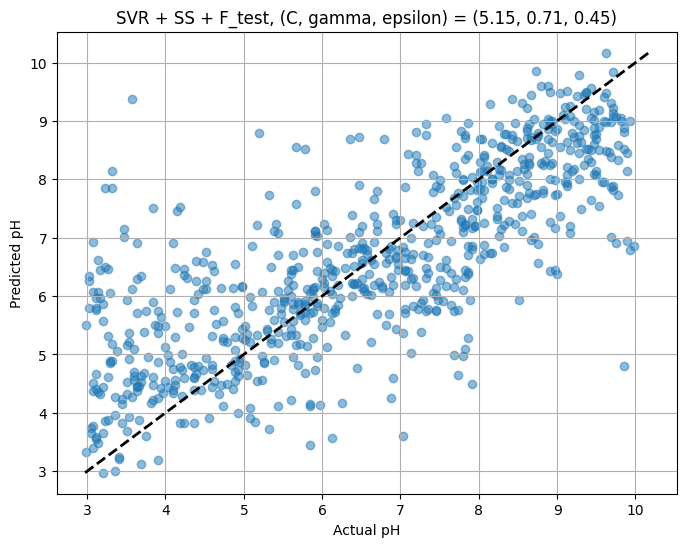

In [40]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SS + F_test"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_ss_F_test, y_train)
metrics_calculation(svr, X_train_ss_F_test, y_train, X_test_ss_F_test, y_test,
                    f'SVR + SS + F_test, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SS + F_test, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

##### **SVR + SFS**

In [52]:
optimizer = BayesianOptimization(f=objective_wrapper(X_train_sfs, X_test_sfs, y_train, y_test), pbounds=pbounds,
                                 random_state=42, verbose=2)
optimizer.maximize(init_points=5, n_iter=200)

best = optimizer.max
if best is None:
    raise RuntimeError("Bayesian optimization produced no result; ensure maximize() completed.")
print(f"Best params: {best['params']}")
p, target = best['params'], best['target']
svr_training.loc[len(svr_training)] = ['SVR + SFS', target, 10**p['log_C'], 10**p['log_gamma'], p['epsilon']]

|   iter    |  target   |   log_C   | log_gamma |  epsilon  |
-------------------------------------------------------------
| 1         | -4.034752 | 1.1236203 | 0.8028572 | 0.7322619 |


| 2         | -1.467600 | 1.7959754 | -2.375925 | 0.1568385 |
| 3         | -4.032850 | 0.1742508 | 0.4647045 | 0.6015138 |
| 4         | -1.541674 | 2.1242177 | -2.917662 | 0.9699399 |
| 5         | -1.752154 | 2.4973279 | -2.150643 | 0.1826431 |
| 6         | -1.774848 | 0.0       | -3.0      | 0.0010000 |
| 7         | -1.805417 | 2.2688915 | -3.0      | 0.001     |
| 8         | -1.538292 | 0.6219181 | -3.0      | 1.0       |
| 9         | -1.456297 | 1.2701007 | -1.976604 | 1.0       |
| 10        | -1.287990 | 0.8227975 | -2.076734 | 0.001     |
| 11        | -1.527333 | 0.0       | -2.106528 | 1.0       |
| 12        | -1.223208 | 0.8662166 | -2.411141 | 0.4656238 |
| 13        | -1.342965 | 0.9984871 | -2.627503 | 0.001     |
| 14        | -1.392859 | 0.0       | -1.985982 | 0.001     |
| 15        | -1.225107 | 0.4970258 | -2.226348 | 0.3647101 |
| 16        | -1.247825 | 0.7304358 | -2.061408 | 0.4679706 |
| 17        | -1.247334 | 0.7119220 | -2.317527 | 0.7193131 |
| 18    

--- SVR + SFS, (C, gamma, epsilon) = (5.50, 0.01, 0.36) ---
Training RMSE: 0.7405
Testing RMSE: 1.0964
Training R²: 0.8641
Testing R²: 0.7019


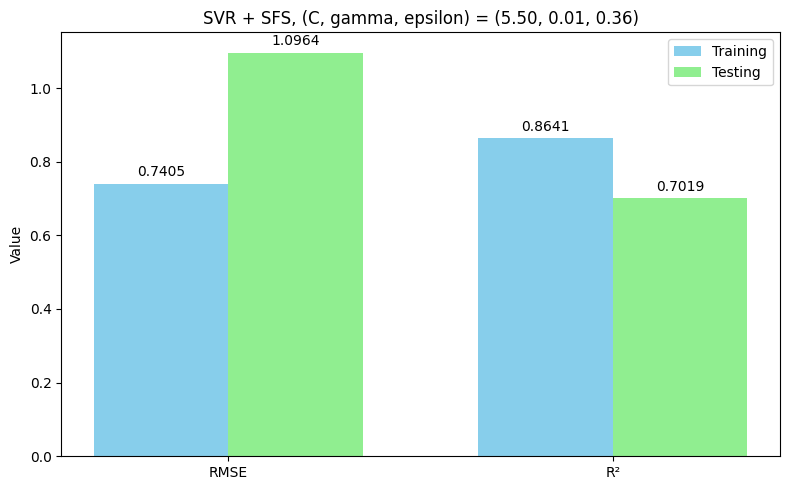

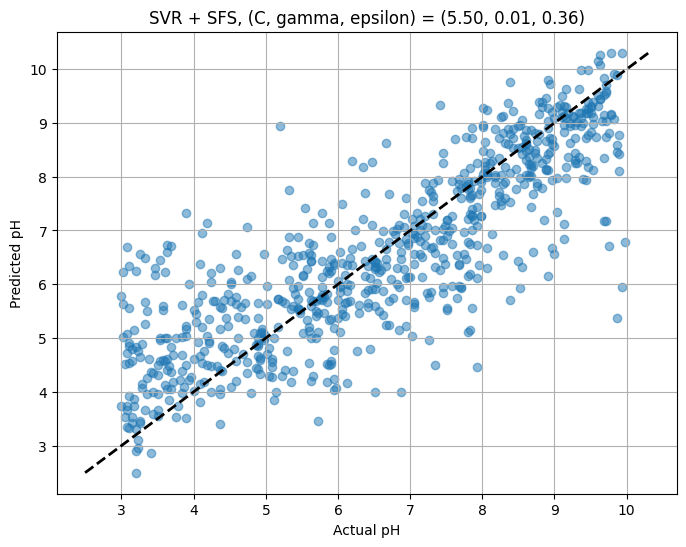

In [54]:
C, gamma, epsilon = svr_training.loc[svr_training['Method'] == "SVR + SFS"
                                    , ['Best_C', 'Best_gamma', 'Best_epsilon']].iloc[-1]
svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(X_train_sfs, y_train)
metrics_calculation(svr, X_train_sfs, y_train, X_test_sfs, y_test,
                    f'SVR + SFS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})',
                    f'SVR + SFS, (C, gamma, epsilon) = ({C:.2f}, {gamma:.2f}, {epsilon:.2f})')

#### **CNN**

In [12]:
model_cnn = models.Sequential()

# Input layer
model_cnn.add(layers.Input(shape=(18, 1), name='input_layer'))

# Block 1
model_cnn.add(layers.Conv1D(filters=8, kernel_size=10, strides=1,
                            padding='same', name='conv1'))
model_cnn.add(layers.BatchNormalization(name='bn1'))
model_cnn.add(layers.Activation('relu', name='act1'))
model_cnn.add(layers.AveragePooling1D(pool_size=2, strides=2, name='avgpool1'))

# Block 2
model_cnn.add(layers.Conv1D(filters=16, kernel_size=5, strides=1,
                        padding="same", name="conv2"))
model_cnn.add(layers.BatchNormalization(name="bn2"))
model_cnn.add(layers.Activation("relu", name="act2"))
model_cnn.add(layers.AveragePooling1D(pool_size=2, strides=2, name="avgpool2"))

#Block 3
model_cnn.add(layers.Conv1D(filters=32, kernel_size=3, strides=1,
                            padding="same", name="conv3"))
model_cnn.add(layers.BatchNormalization(name="bn3"))
model_cnn.add(layers.Activation("relu", name="act3"))
model_cnn.add(layers.AveragePooling1D(pool_size=2, strides=2, name="avgpool3"))

# Flatten
model_cnn.add(layers.Flatten(name="flatten1"))
model_cnn.add(layers.Dropout(0.20, name="dropout1"))
model_cnn.add(layers.Activation("sigmoid", name="act4"))

# Fully connected + Output
model_cnn.add(layers.Dense(30, activation='relu', name="fc1"))
model_cnn.add(layers.Dense(1, activation='relu', name="output"))

In [4]:
model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv1D)                  │ (None, 18, 8)          │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 18, 8)          │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act1 (Activation)               │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool1 (AveragePooling1D)     │ (None, 9, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 9, 16)          │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 9, 16)          │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act2 (Activation)               │ (None, 9, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool2 (AveragePooling1D)     │ (None, 4, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 4, 32)          │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 4, 32)          │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act3 (Activation)               │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool3 (AveragePooling1D)     │ (None, 2, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten1 (Flatten)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act4 (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 30)             │         1,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,517 (17.64 KB)

 Trainable params: 4,405 (17.21 KB)

 Non-trainable params: 112 (448.00 B)

In [13]:
model_cnn.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss=tf.keras.losses.MeanSquaredError())

In [14]:
model_cnn.fit(X_train_ss, y_train, batch_size=256, epochs=2000)

Epoch 1/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 44.6873
Epoch 2/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 34.5541
Epoch 3/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 23.8931
Epoch 4/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 15.6618
Epoch 5/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 9.9552 
Epoch 6/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.4556
Epoch 7/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4.6320
Epoch 8/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.0005
Epoch 9/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.9593
Epoch 10/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.9514
Epoch 11/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.8511
Epoch 12/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.7154
Epoch 13/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.6001
Epoch 14/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.5086
Epoch 15/2000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.4432

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
--- CNN ---
Training RMSE: 0.3831
Testing RMSE: 1.2968
Training R²: 0.9636
Testing R²: 0.5829


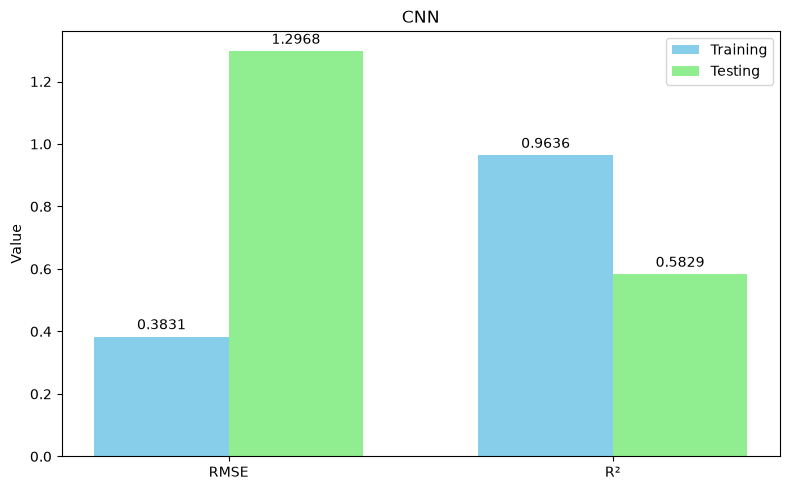

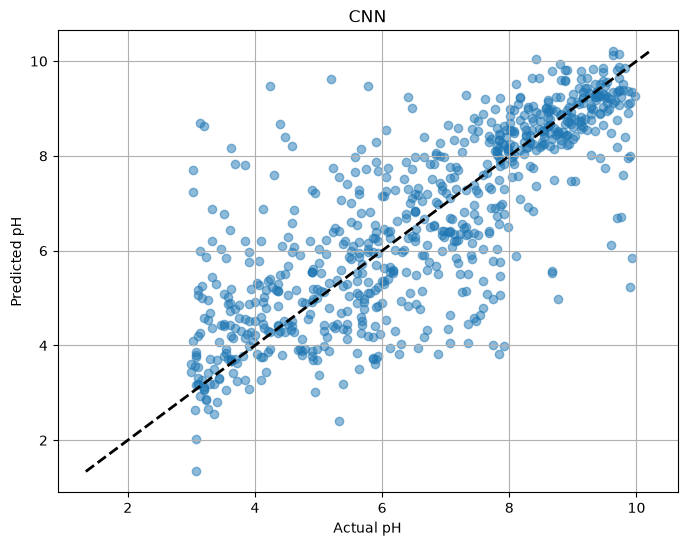

In [15]:
metrics_calculation(model_cnn, X_train_ss, y_train, X_test_ss, y_test,
                    f'CNN',
                    f'CNN')